# Publication benchmark analysis

**Source run:** chosen in the configuration cell (the augmented `_aug` copy when it exists)  
**Protocol:** publication-v6-fresh-cached-scoring

This notebook replaces the final-state parts of `analyze_results_v2.ipynb` and
`analyze_synthetic_gt_v2.ipynb` for the new experiment schema. It combines a coverage
audit, predictive performance, paired selection-time speedups, serial/parallel and
shadow ablations, synthetic recovery, stability, memory, and prespecified
non-inferiority diagnostics. All calculations use this run alone.

**Run all cells to refresh.** The run may still be in progress. The first section
reports exactly what was read; comparative figures use only complete
**dataset × data seed × alpha** blocks with every planned method/policy and every
CV split present. Final inferential decisions are withheld until the full design
is complete. No models are fitted and no source logs are modified.

## 1. Configuration and reproducible input audit

Paths work from the repository root or this notebook directory. `FOCUS_ALPHA`
controls the detailed cost/performance and NI figures; the heatmaps retain every
planned alpha. `j` in plot labels is outer worker count and `s` is shadow fraction.
A common CPU budget is shared across outer workers.

In [1]:
from pathlib import Path
import sys
import json
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "benchmarks" / "runner" / "experiment_run.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Launch Jupyter from within this repository")
ANALYSIS_DIR = ROOT / "benchmarks" / "analysis" / "publication"
if str(ANALYSIS_DIR) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_DIR))
import analysis_helpers as ah

# Prefer the augmented copy (runner/augment_coupled.py) when it exists; it adds GreedyCoupled.
RUNS = ROOT / "benchmarks" / "data" / "publication_runs"
RUN_DIR = next(p for p in [RUNS / f"{ah.RUN_NAME}_aug", RUNS / ah.RUN_NAME] if p.exists())
FOCUS_ALPHA = 0.001
OUTPUT_DIR = ANALYSIS_DIR / "outputs" / RUN_DIR.name
ah.apply_theme()
pd.set_option("display.max_columns", 14)
pd.set_option("display.max_rows", 60)
pd.set_option("display.precision", 4)

# Each figure is both displayed inline and exported.
def show(fig, name):
    ah.save_figure(fig, OUTPUT_DIR, name)
    display(fig)
    plt.close(fig)

**COMPLETE DESIGN**  
Read interval (UTC): 2026-10-18T16:06:47.532693+00:00 to 2026-10-18T16:06:48.421799+00:00  
Checkpoint rows: **3,465 / 3,465**. Rows in complete comparison blocks: **3,465**.  
Recorded progress status: `complete` (this status is metadata, not proof that a process is currently active).

Observed_Rows  Expected_Rows  Complete_Groups  \
Suite     Dataset                                                          
synthetic reference                  315            315               21   
          n_features_2000            315            315               21   
          signal_0.5                 315            315               21   
          kind_xor                   315            315               21   
          kind_null                  315            315               21   
real      Madelon                    315            315               21   
          Arcene                     315            315               21   
          Gisette                    315            315               21   
          Dexter                     315            315               21   
          Riboflavin                 315            315               21   
          Isolet                     315            315               21   

                           Planned_Groups  
Suite     Dataset                          
synthetic reference                    21  
          n_features_2000              21  
          signal_0.5                   21  
          kind_xor                     21  
          kind_null                    21  
real      Madelon                      21  
          Arcene                       21  
          Gisette                      21  
          Dexter                       21  
          Riboflavin                   21  
          Isolet                       21

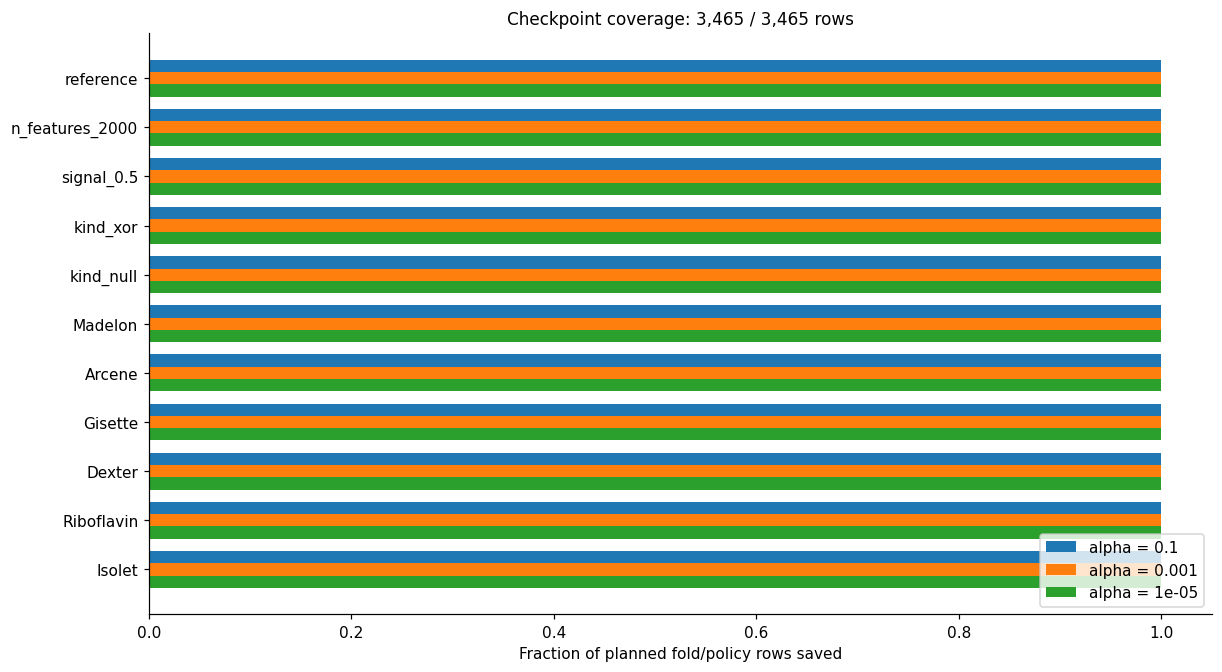

In [2]:
run = ah.load_run(RUN_DIR)
config = run.manifest["config"]
assert FOCUS_ALPHA in config["alphas"], "Choose a manifest alpha"
observed = run.frame
complete = ah.complete_blocks(run)
status = "COMPLETE DESIGN" if run.complete else "PARTIAL RUN — final NI decisions withheld"
display(Markdown(f"**{status}**  \nRead interval (UTC): {run.provenance['read_started_utc']} to "
                 f"{run.provenance['read_finished_utc']}  \n"
                 f"Checkpoint rows: **{len(observed):,} / {run.manifest['workload']['result_rows']:,}**. "
                 f"Rows in complete comparison blocks: **{len(complete):,}**.  \n"
                 f"Recorded progress status: `{run.progress.get('status', 'unavailable')}` "
                 "(this status is metadata, not proof that a process is currently active)."))
coverage = run.coverage.groupby(["Suite", "Dataset"], sort=False).agg(
    Observed_Rows=("Observed", "sum"), Expected_Rows=("Expected", "sum"),
    Complete_Groups=("Complete", "sum"), Planned_Groups=("Complete", "size"))
display(coverage)
show(ah.coverage_plot(run), "01_coverage")
if complete.empty:
    raise RuntimeError("No complete comparison blocks yet; rerun after more jobs finish")

In [3]:
design = pd.DataFrame([dict(Dataset=name, Suite=kind,
    Task="class" if kind == "synthetic" else spec[1],
    Specification=json.dumps(spec, sort_keys=True))
    for name, (kind, spec) in config["datasets"].items()])
display(design)
display(pd.DataFrame(config["methods"]))
display(pd.Series({"Protocol": run.manifest["protocol"], "Created UTC": run.manifest["created_utc"],
                   "Repeats": config["repeats"], "Folds": config["folds"],
                   "Data seeds": config["data_seeds"], "CPU budget": config["cpu_budget"],
                   "Alphas": config["alphas"], "Vanilla iteration ceiling": config["vanilla_iterations"],
                   "F1 loss margin": config["f1_margin"], "R² loss margin": config["r2_margin"],
                   "NI test level": config["test_level"]}, name="Frozen design"))

,Dataset,Suite,Task,Specification
0,reference,synthetic,class,"{""correlation"": 0.8, ""kind"": ""linear"", ""n_corr..."
1,n_features_2000,synthetic,class,"{""correlation"": 0.8, ""kind"": ""linear"", ""n_corr..."
2,signal_0.5,synthetic,class,"{""correlation"": 0.8, ""kind"": ""linear"", ""n_corr..."
3,kind_xor,synthetic,class,"{""correlation"": 0.8, ""kind"": ""xor"", ""n_correla..."
4,kind_null,synthetic,class,"{""correlation"": 0.8, ""kind"": ""null"", ""n_correl..."
5,Madelon,real,class,"[1485, ""class""]"
6,Arcene,real,class,"[1458, ""class""]"
7,Gisette,real,class,"[41026, ""class""]"
8,Dexter,real,class,"[4136, ""class""]"
9,Riboflavin,real,reg,"[46983, ""reg""]"


,name,outer,inner,shadows
0,NoSelection,1,28,NaN
1,Vanilla,1,28,NaN
2,Greedy_jobs1_shadows1,1,28,1.00
3,Greedy_jobs7_shadows1,7,4,1.00
4,Greedy_jobs7_shadows0.25,7,4,0.25
5,Greedy_jobs7_shadows0.1,7,4,0.10


Protocol                     publication-v6-fresh-cached-scoring
Created UTC                     2026-09-26T13:25:46.794409+00:00
Repeats                                                        3
Folds                                                          5
Data seeds                                                   [0]
CPU budget                                                    28
Alphas                                       [0.1, 0.001, 1e-05]
Vanilla iteration ceiling                                    512
F1 loss margin                                              0.01
R² loss margin                                              0.01
NI test level                                               0.01
Name: Frozen design, dtype: object

### Interpretation and units

- **Prediction:** weighted F1 for classification; R² for regression. Neither is
  feature-recovery F1. Scores are never pooled across different tasks or datasets.
- **Repeated CV:** folds and repeats overlap. Standard deviations and IQRs below
  describe dispersion; they are not confidence intervals assuming independent folds.
- **Timing:** compare selection time on identical split/alpha pairs. Both Vanilla
  policies come from one fit. NoSelection is duplicated across alpha without new
  fits. A cache hit reuses an exact mask's downstream score and original score cost;
  `Downstream_Actual_Time_Sec` is the field used for actual resource accounting.
- **Incomplete blocks:** coverage and observed summaries include all saved rows.
  Comparative plots exclude incomplete blocks so method groups have matched support.
  Missing datasets are not evidence of poor performance.
- **Checkpoint meaning:** these are final job checkpoints, not iteration histories.
  Convergence trajectories, tentative-state metrics, and earliest-equivalence
  thresholds from the older notebooks cannot be recovered from these logs.

## 2. Predictive performance and selection cost

The table gives mean score, fold SD, valid count and median selection cost for the
focus alpha. The scatter uses mean score and median selector runtime; the dotted
line shows the all-feature predictor. These points describe a cost/performance
tradeoff, not an inferential Pareto claim. Unrestricted R² axes allow negative scores.

,Dataset,Data_Seed,Task,Label,Score_mean,Score_std,Score_count,Selection_Time_Sec_median,N_Selected_mean
7,Arcene,0,class,"Greedy j=1, s=1",0.8095,0.0671,15,4.9311e+01,407.2667
8,Arcene,0,class,"Greedy j=7, s=0.1",0.8255,0.0518,15,1.1001e+01,973.4667
9,Arcene,0,class,"Greedy j=7, s=0.25",0.8276,0.0562,15,1.1327e+01,684.6667
10,Arcene,0,class,"Greedy j=7, s=1",0.8095,0.0671,15,1.3073e+01,407.2667
11,Arcene,0,class,All features,0.7701,0.0802,15,3.2300e-05,10000.0000
...,...,...,...,...,...,...,...,...,...
219,signal_0.5,0,class,"Greedy j=7, s=0.25",0.5344,0.0298,15,2.3896e+00,29.5333
220,signal_0.5,0,class,"Greedy j=7, s=1",0.5356,0.0378,15,2.6288e+00,13.6000
221,signal_0.5,0,class,All features,0.5283,0.0336,15,3.3300e-05,500.0000
222,signal_0.5,0,class,Vanilla rough fix,0.5359,0.0282,15,4.5416e+01,13.7333


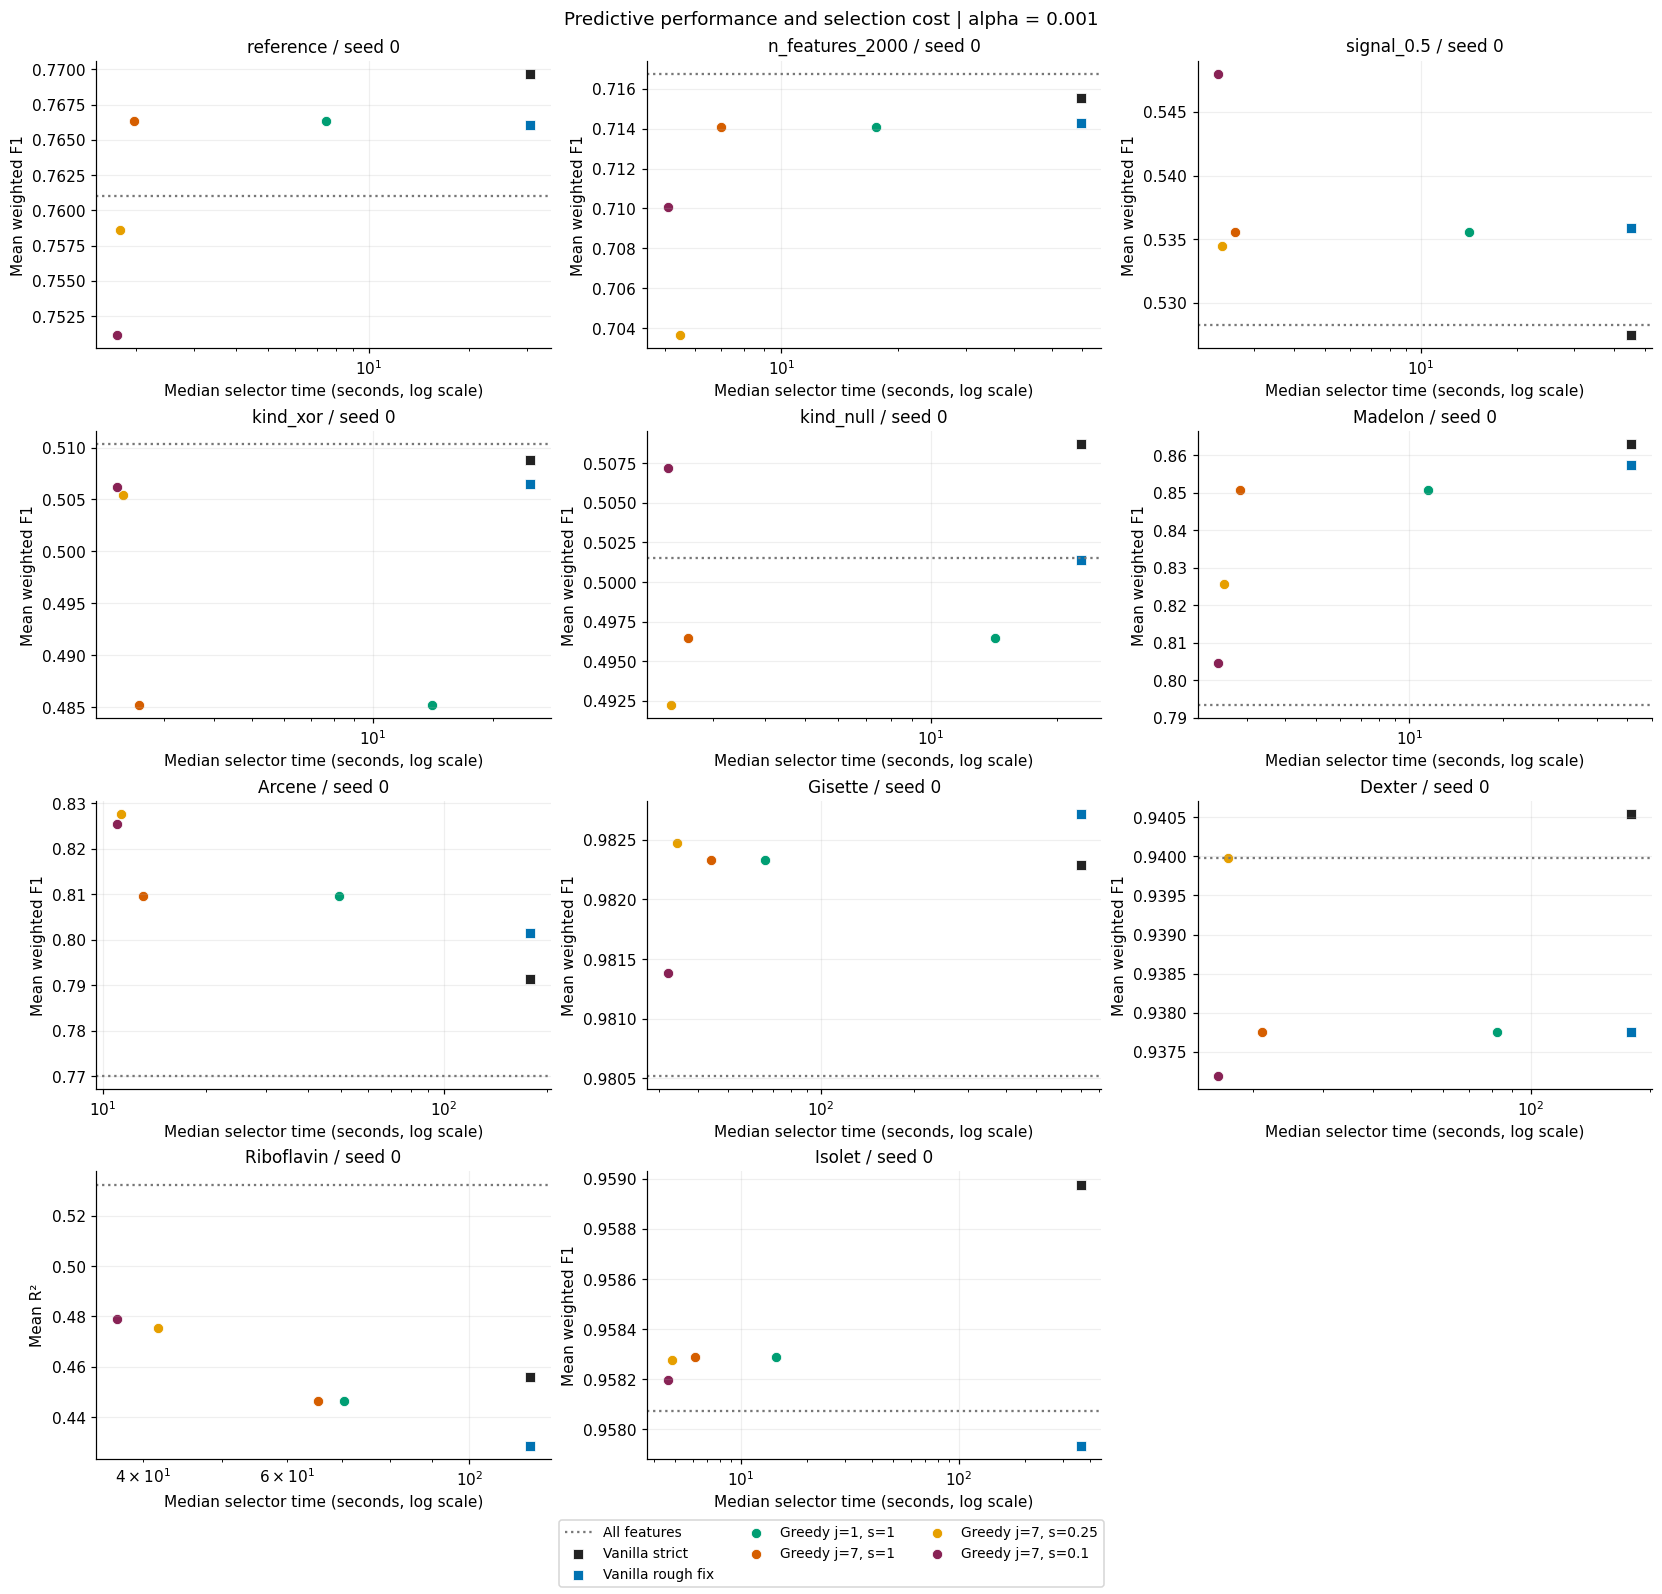

In [4]:
observed_summary = ah.summary_table(observed)
summary = ah.summary_table(complete)
paired = ah.paired_comparisons(complete)
speedups = ah.speedup_summary(paired)
focus_summary = summary[summary.Alpha.eq(FOCUS_ALPHA)]
display(focus_summary[["Dataset", "Data_Seed", "Task", "Label", "Score_mean", "Score_std",
                       "Score_count", "Selection_Time_Sec_median", "N_Selected_mean"]])
show(ah.score_runtime_plot(complete, FOCUS_ALPHA), "02_score_vs_selection_time")

### Paired score differences across all alphas

Each cell is the mean of candidate score minus **Vanilla rough fix** on the exact
same repeat, fold, split hash and train/test sizes. Positive values favor the
candidate. Classification and regression are rendered separately.

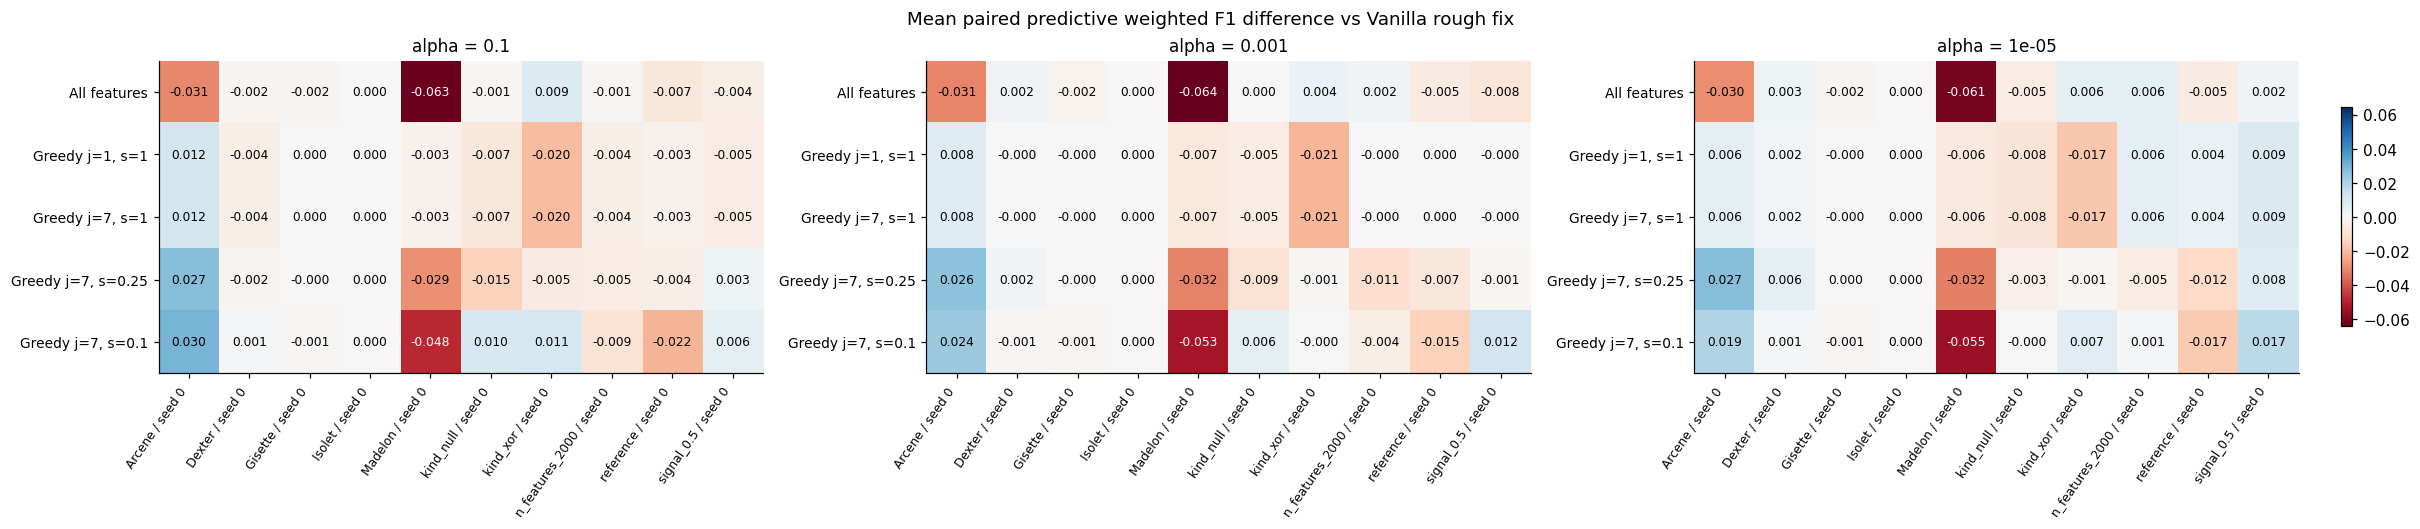

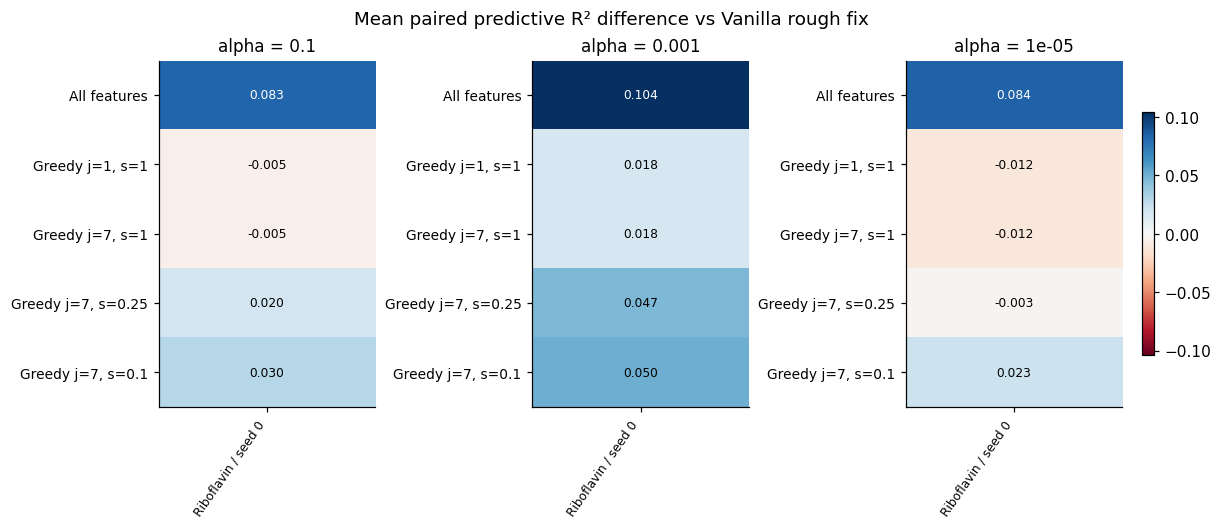

In [5]:
for task, label in [("class", "weighted F1"), ("reg", "R²")]:
    subset = paired[paired.Task.eq(task)]
    if subset.empty:
        display(Markdown(f"No complete {task} blocks available in this snapshot."))
        continue
    show(ah.heatmap(subset, "Score_Difference", f"Mean paired predictive {label} difference vs Vanilla rough fix",
                    center=True, fmt=".3f"), f"03_score_difference_{task}")

### Paired speedups, selected fraction, and iterations

Speedup is computed **within each pair** as Vanilla selection time / Greedy
selection time, then summarized. Values above one favor Greedy. It is not the ratio
of separately averaged runtimes. NoSelection has no selector speedup. The timing
policy uses Vanilla rough fix as a reference; its strict policy has the same cost.
The exported speedup table also contains the IQR and geometric mean.

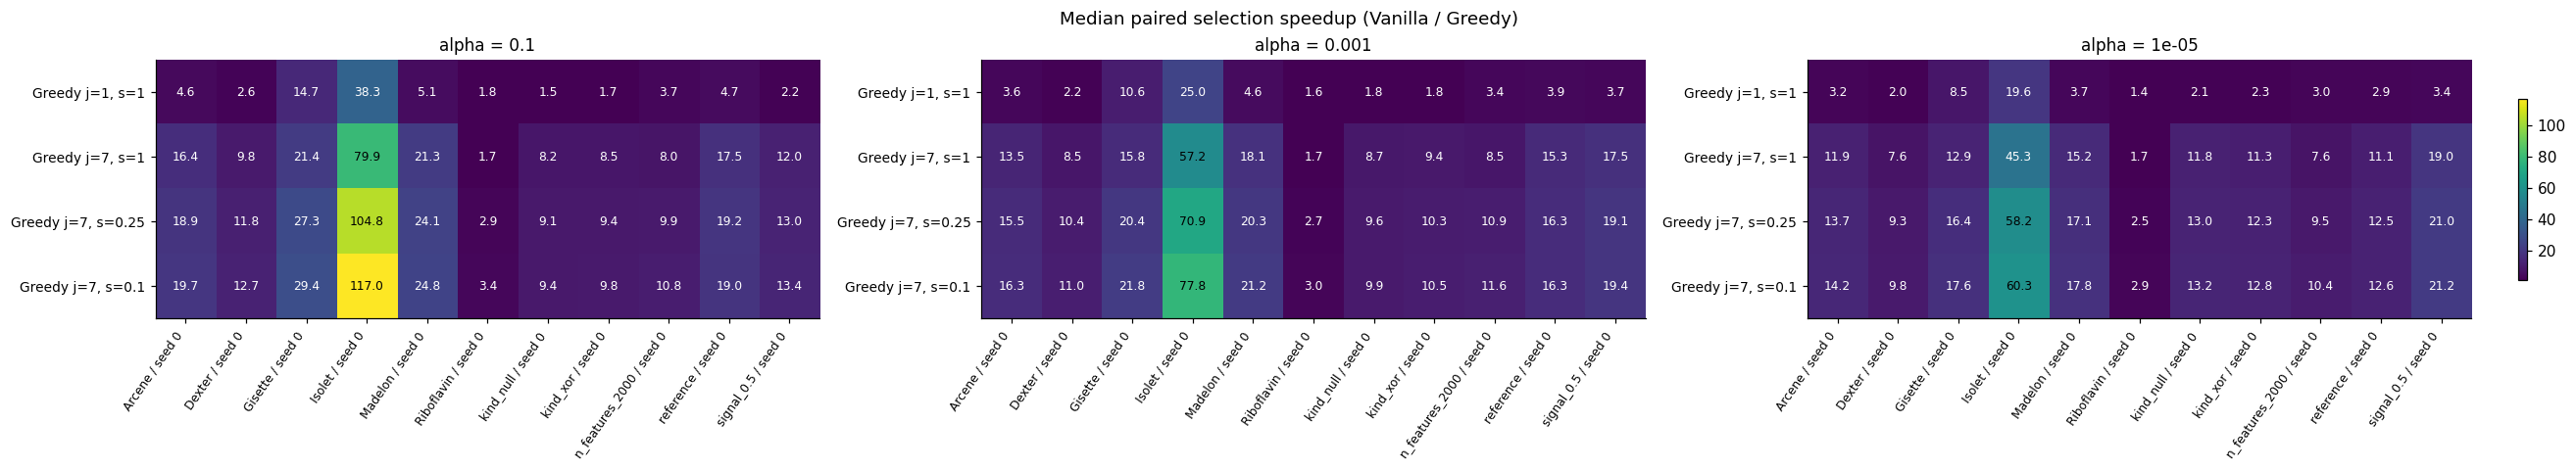

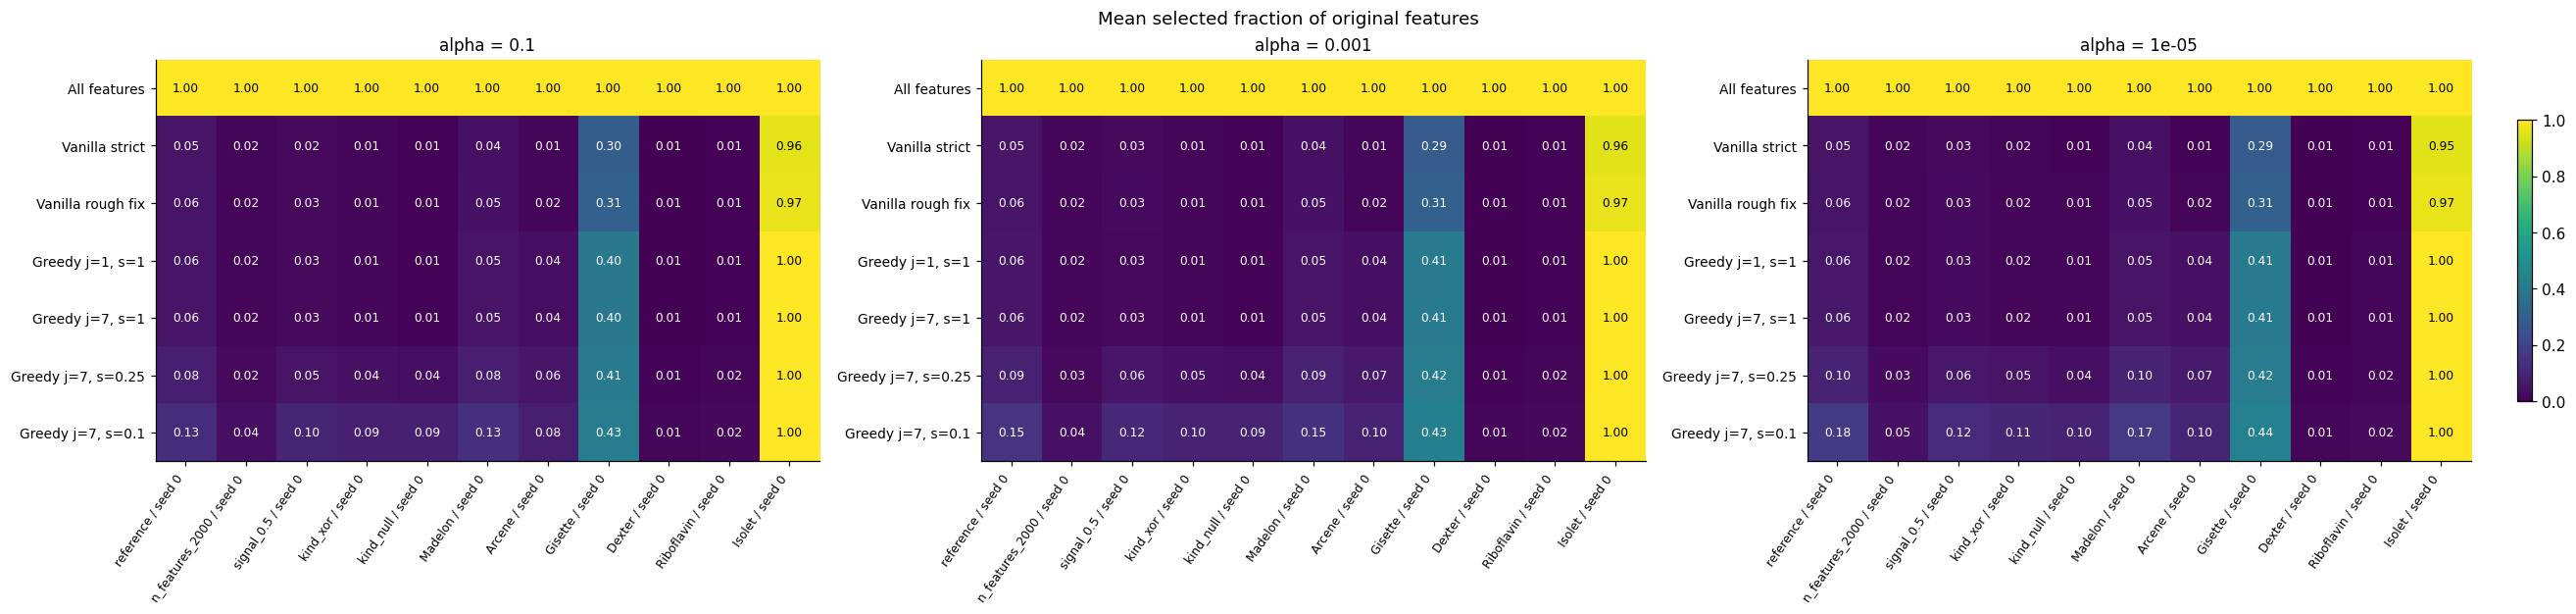

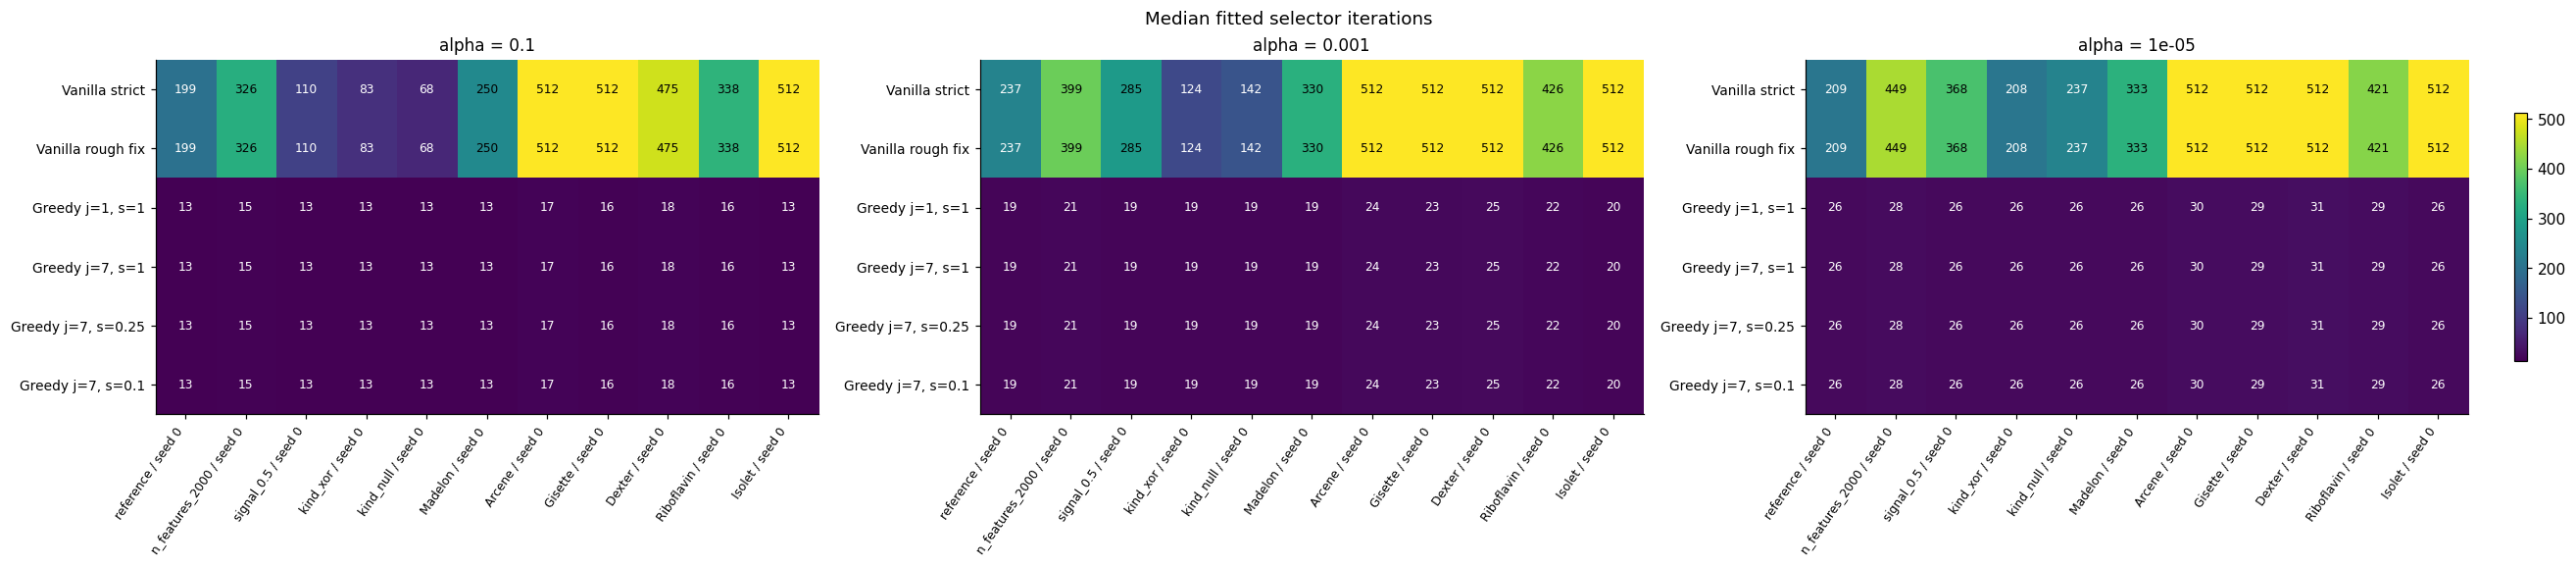

,Dataset,Label,Median,Q25,Q75,Geometric_Mean,N_Pairs
4,Arcene,"Greedy j=1, s=1",3.6299,3.5074,3.6832,3.6529,15
5,Arcene,"Greedy j=7, s=0.1",16.2866,15.7100,16.5808,16.3503,15
6,Arcene,"Greedy j=7, s=0.25",15.5365,15.0697,16.0970,15.8723,15
7,Arcene,"Greedy j=7, s=1",13.5206,13.2454,13.8131,13.6953,15
16,Dexter,"Greedy j=1, s=1",2.1681,2.0385,2.2048,2.1150,15
17,Dexter,"Greedy j=7, s=0.1",10.9984,10.2454,11.1397,10.6767,15
18,Dexter,"Greedy j=7, s=0.25",10.3827,9.3472,10.4770,9.8981,15
19,Dexter,"Greedy j=7, s=1",8.5029,7.6779,8.6267,8.0622,15
28,Gisette,"Greedy j=1, s=1",10.5711,10.5025,10.6389,10.5765,15
29,Gisette,"Greedy j=7, s=0.1",21.7954,21.6555,21.9480,21.7661,15


In [6]:
greedy_pairs = paired[paired.Method.str.startswith("Greedy")]
show(ah.heatmap(greedy_pairs, "Speedup", "Median paired selection speedup (Vanilla / Greedy)",
                agg="median", fmt=".1f"), "04_paired_speedup")
show(ah.heatmap(complete, "Selected_Fraction", "Mean selected fraction of original features",
                bounds=(0, 1)), "05_selected_fraction")
selectors = complete[~complete.Method.eq("NoSelection")]
show(ah.heatmap(selectors, "Iterations", "Median fitted selector iterations", agg="median", fmt=".0f"),
     "06_iterations")
display(speedups[speedups.Alpha.eq(FOCUS_ALPHA)][["Dataset", "Label", "Median", "Q25", "Q75", "Geometric_Mean", "N_Pairs"]])

## 3. Outer-worker and shadow ablations

Compare the parallel run (j>1) with j=1 on the same data split, alpha and actual shadow
count. Both receive the frozen total CPU budget (28 here): the serial estimator receives
28 threads and each of the j outer workers receives 28/j (seven workers x four threads here). A speedup below one indicates
parallel overhead exceeds the benefit for that configuration. Identical masks are
checked explicitly rather than assumed. The six Greedy rows in all-alpha plots
also expose the shadow-fraction ablation at fixed outer-worker count.

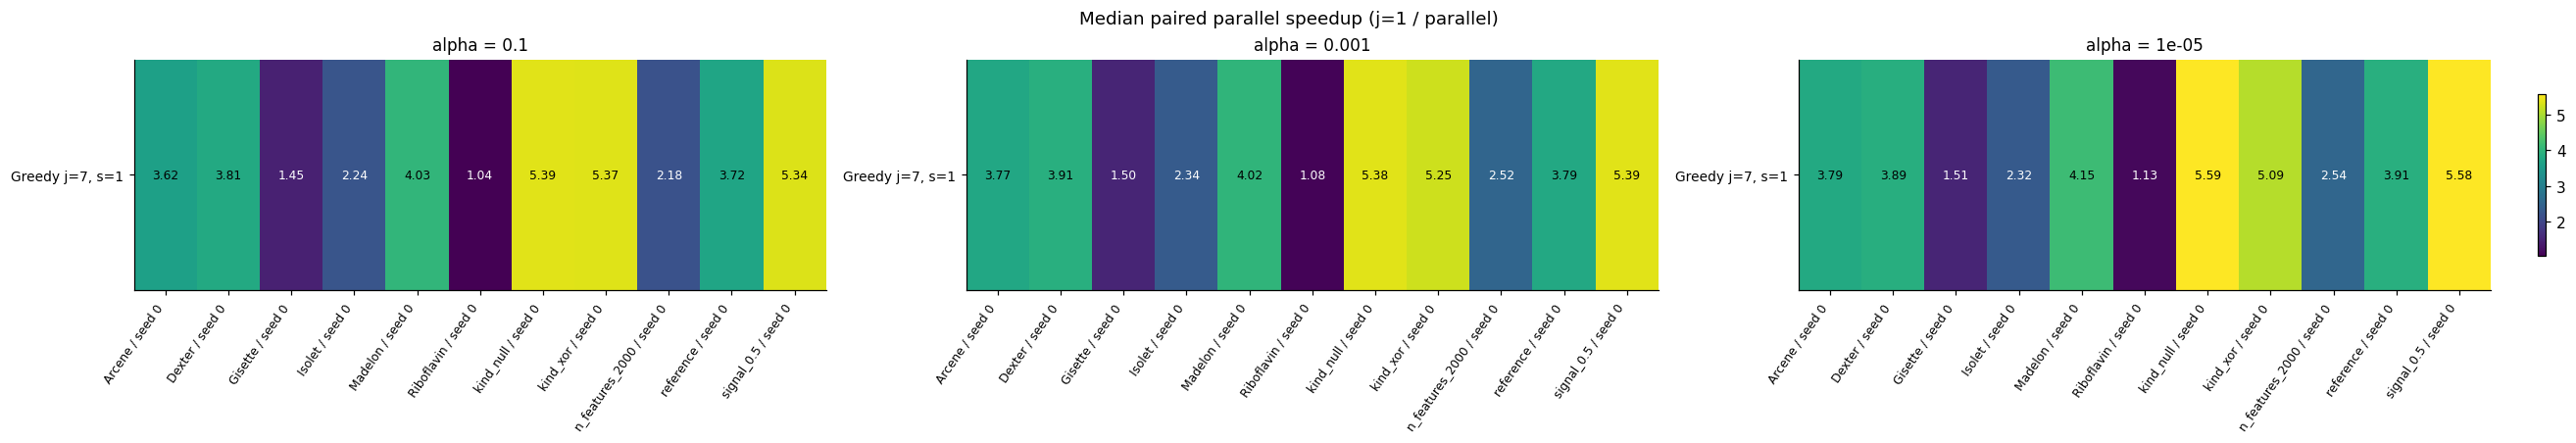

,Dataset,Label,N_Pairs,Median_Speedup,Identical_Mask_Fraction,Mean_Score_Difference
1,Arcene,"Greedy j=7, s=1",15,3.7663,1.0,0.0
4,Dexter,"Greedy j=7, s=1",15,3.9136,1.0,0.0
7,Gisette,"Greedy j=7, s=1",15,1.5007,1.0,0.0
10,Isolet,"Greedy j=7, s=1",15,2.3397,1.0,0.0
13,Madelon,"Greedy j=7, s=1",15,4.0151,1.0,0.0
16,Riboflavin,"Greedy j=7, s=1",15,1.0827,1.0,0.0
19,kind_null,"Greedy j=7, s=1",15,5.3825,1.0,0.0
22,kind_xor,"Greedy j=7, s=1",15,5.2481,1.0,0.0
25,n_features_2000,"Greedy j=7, s=1",15,2.5172,1.0,0.0
28,reference,"Greedy j=7, s=1",15,3.7910,1.0,0.0


In [7]:
parallel = ah.parallel_ablation(complete)
show(ah.heatmap(parallel, "Parallel_Speedup", "Median paired parallel speedup (j=1 / parallel)",
                agg="median"), "07_parallel_speedup")
parallel_summary = parallel.groupby(ah.GROUP + ["Label"]).agg(
    N_Pairs=("Parallel_Speedup", "size"), Median_Speedup=("Parallel_Speedup", "median"),
    Identical_Mask_Fraction=("Identical_Mask", "mean"),
    Mean_Score_Difference=("Parallel_Score_Difference", "mean")).reset_index()
display(parallel_summary[parallel_summary.Alpha.eq(FOCUS_ALPHA)][
    ["Dataset", "Label", "N_Pairs", "Median_Speedup", "Identical_Mask_Fraction", "Mean_Score_Difference"]])

## 4. Synthetic ground-truth recovery

Ground truth follows the frozen synthetic design and current generator:
**direct predictors + correlated proxies** are relevant; XOR has two direct
predictors, and the null case has none. The loader verifies logged confusion
counts and recovery metrics against the selected feature IDs. The old hard-coded
55-feature broad truth is not used.

Recall is undefined when no true positives exist in the population. Precision is
undefined for an empty selection. These remain missing, not zero or one; summary
CSV columns ending in `_count` give the number of valid values for each metric.
Precision means therefore condition on nonempty selections. FDP is zero for an
empty selection. FPR is FP / number of irrelevant features. Recovery F1 is the
harmonic recovery metric, distinct from predictive weighted F1.

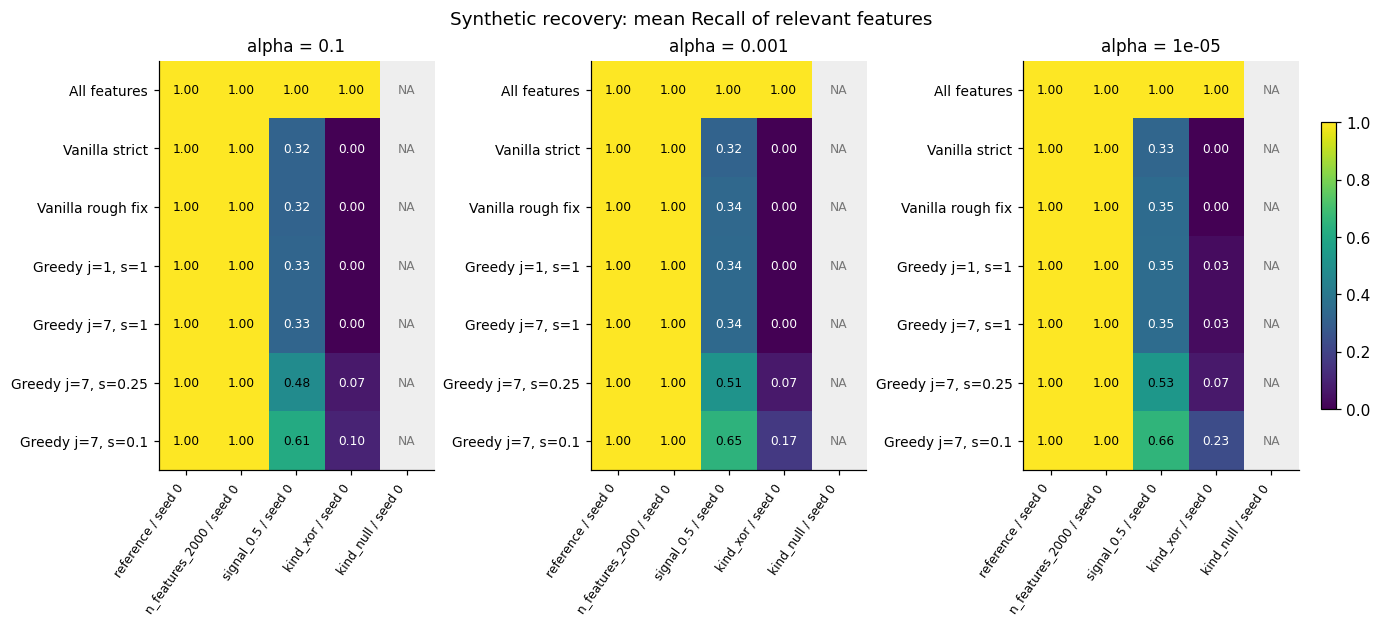

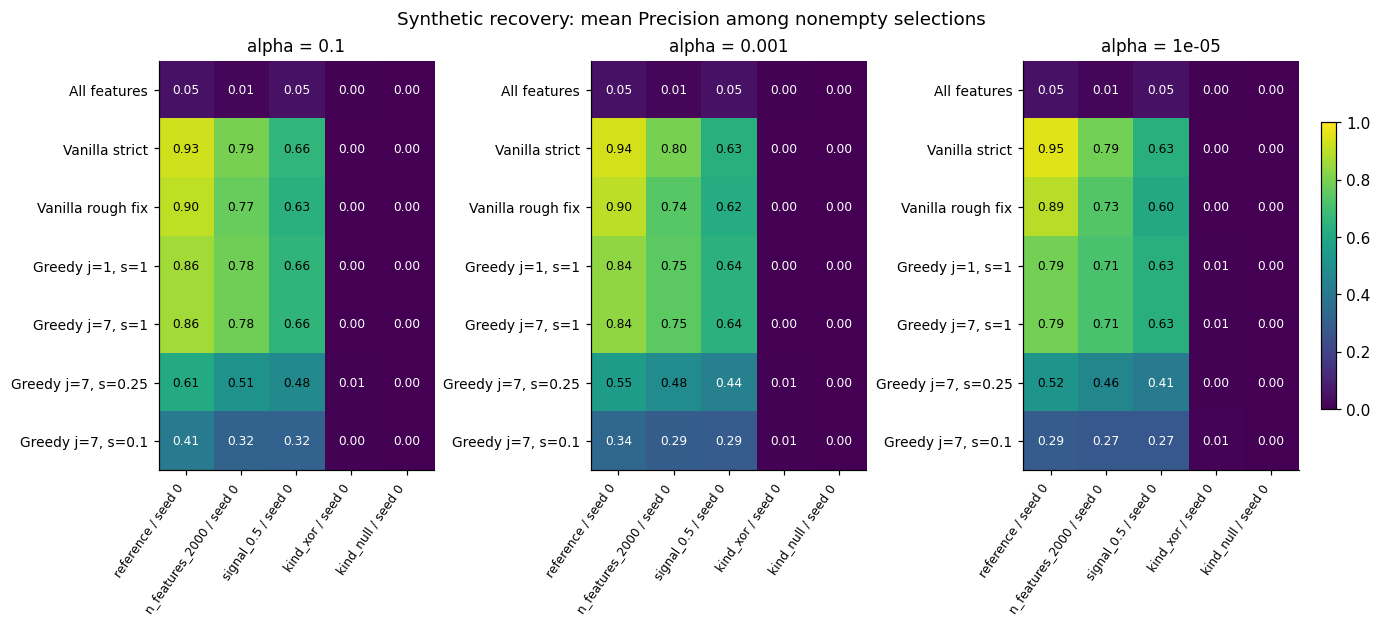

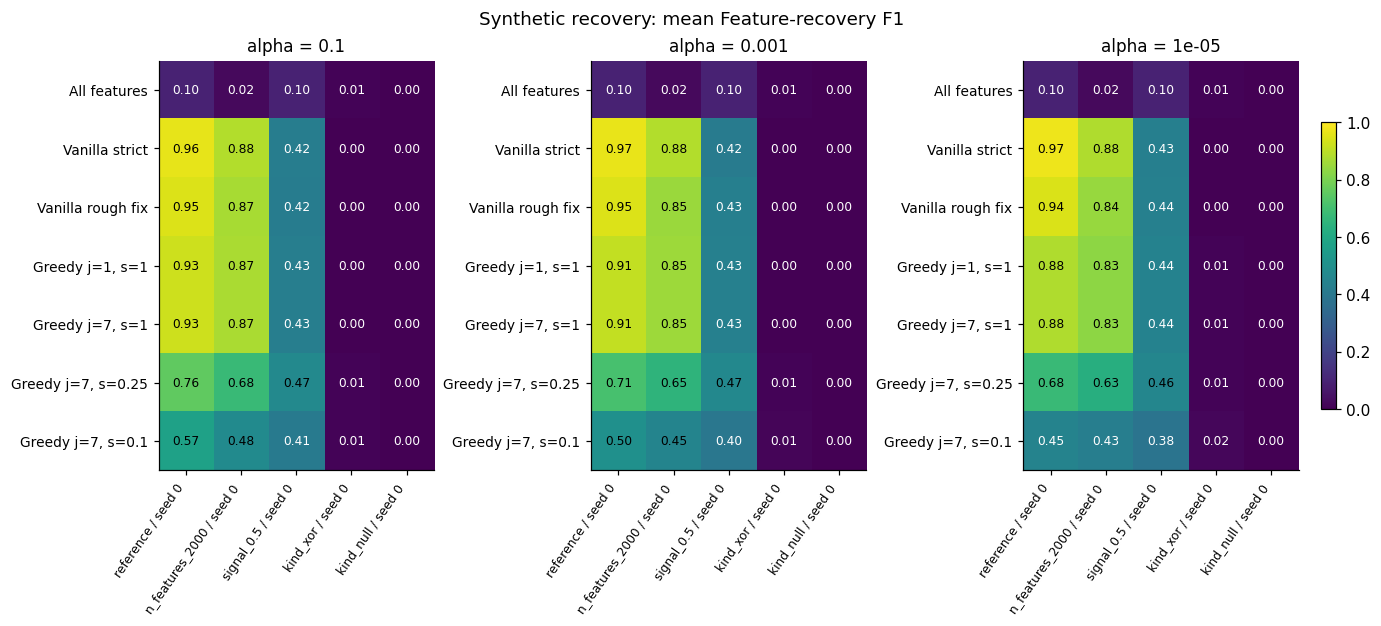

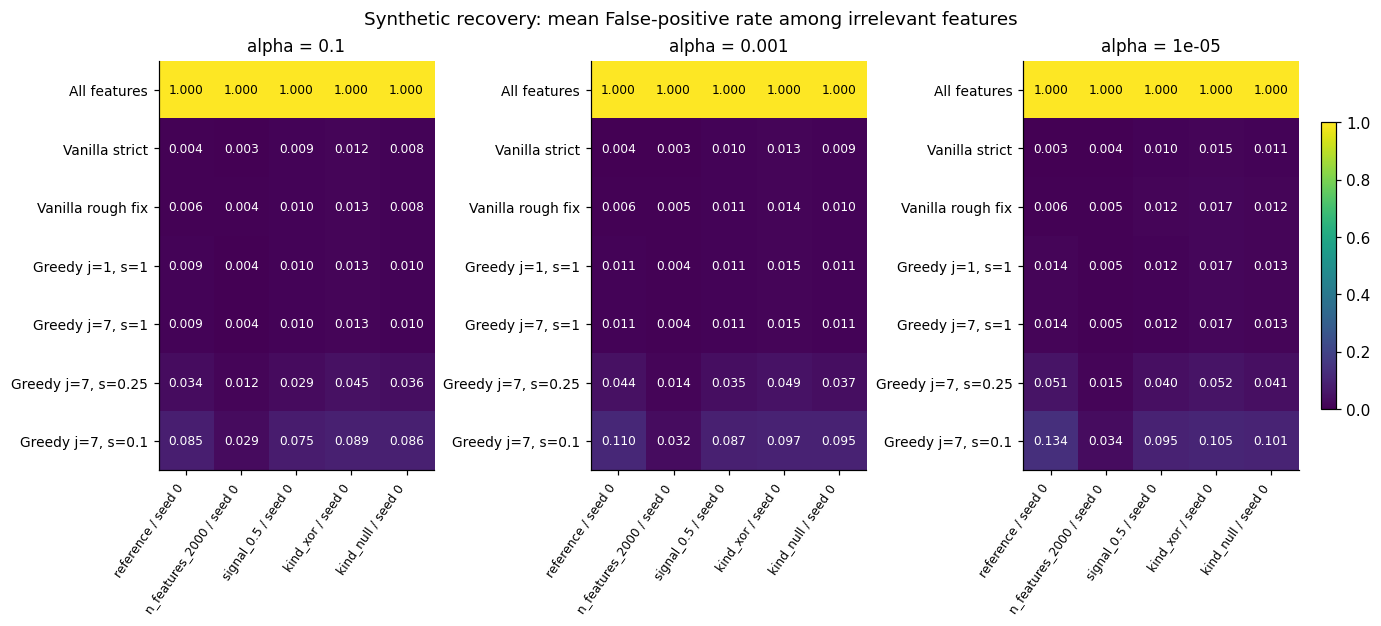

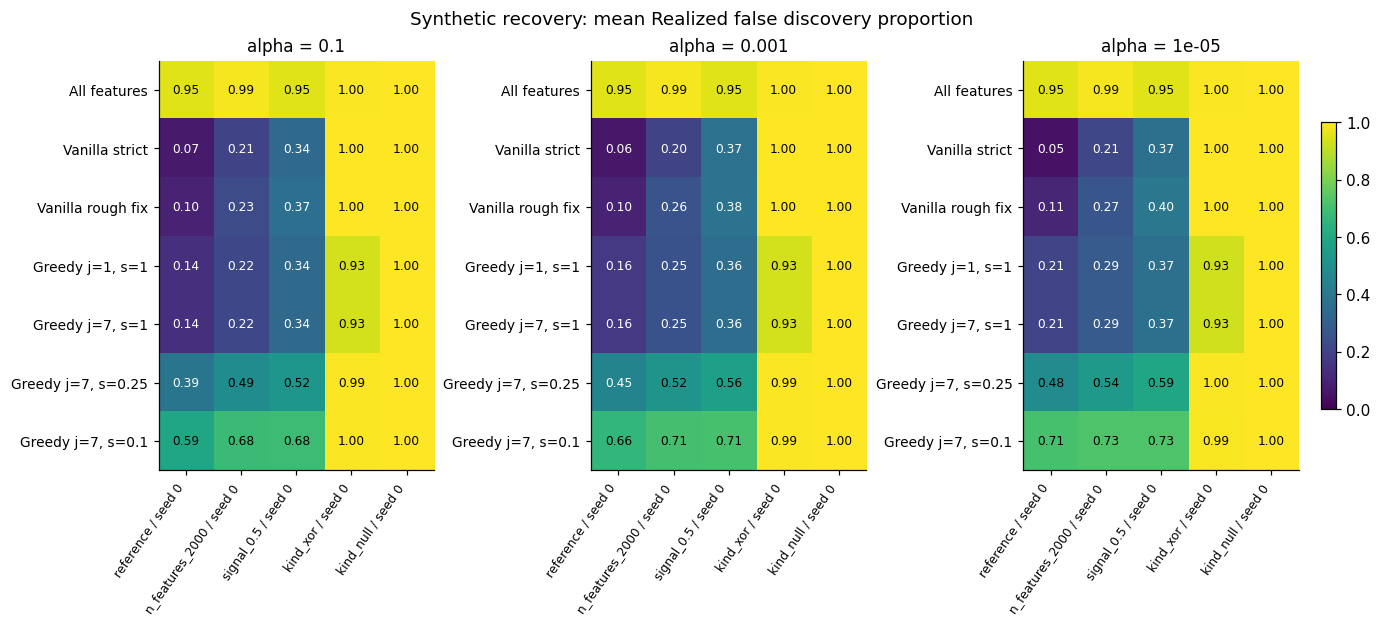

,Dataset,Data_Seed,Alpha,Label,TP_mean,FP_mean,FN_mean,TN_mean,Recall_count,Precision_count,F1_count
133,kind_null,0,0.001,"Greedy j=1, s=1",0.0000,5.5333,0.0000,494.4667,0,15,15
134,kind_null,0,0.001,"Greedy j=7, s=0.1",0.0000,47.4667,0.0000,452.5333,0,15,15
135,kind_null,0,0.001,"Greedy j=7, s=0.25",0.0000,18.5333,0.0000,481.4667,0,15,15
136,kind_null,0,0.001,"Greedy j=7, s=1",0.0000,5.5333,0.0000,494.4667,0,15,15
137,kind_null,0,0.001,All features,0.0000,500.0000,0.0000,0.0000,0,15,15
138,kind_null,0,0.001,Vanilla rough fix,0.0000,5.0000,0.0000,495.0000,0,15,15
139,kind_null,0,0.001,Vanilla strict,0.0000,4.7333,0.0000,495.2667,0,15,15
154,kind_xor,0,0.001,"Greedy j=1, s=1",0.0000,7.4000,2.0000,490.6000,15,14,15
155,kind_xor,0,0.001,"Greedy j=7, s=0.1",0.3333,48.5333,1.6667,449.4667,15,15,15
156,kind_xor,0,0.001,"Greedy j=7, s=0.25",0.1333,24.3333,1.8667,473.6667,15,15,15


In [8]:
synthetic = complete[complete.Suite.eq("synthetic")]
for metric, title in [("Recall", "Recall of relevant features"),
                      ("Precision", "Precision among nonempty selections"),
                      ("F1", "Feature-recovery F1"),
                      ("FPR", "False-positive rate among irrelevant features"),
                      ("FDP", "Realized false discovery proportion")]:
    show(ah.heatmap(synthetic, metric, f"Synthetic recovery: mean {title}", bounds=(0, 1),
                    fmt=".3f" if metric == "FPR" else ".2f"),
         f"08_recovery_{metric.lower()}")
confusion = summary[summary.Suite.eq("synthetic")][
    ["Dataset", "Data_Seed", "Alpha", "Label", "TP_mean", "FP_mean", "FN_mean", "TN_mean",
     "Recall_count", "Precision_count", "F1_count"]]
display(confusion[confusion.Alpha.eq(FOCUS_ALPHA)])

### All-null false selections and XOR

Under the all-null design, every selected feature is false. The proportion of
folds selecting anything, mean FP, and mean FDP distinguish occasional false
selections from large false selections. These are descriptive frequencies on
repeated splits of one realization, not independent estimates of familywise error.
For XOR, use both recovery recall and predictive score: marginally uninformative
features can challenge shallow tree selectors.

In [9]:
null_names = [name for name, (kind, spec) in config["datasets"].items()
              if kind == "synthetic" and spec["kind"] == "null"]
null_summary = summary[summary.Dataset.isin(null_names)][
    ["Dataset", "Alpha", "Label", "Any_Selected_mean", "FP_mean", "FDP_mean", "FPR_mean", "Score_mean"]]
display(null_summary)
xor_names = [name for name, (kind, spec) in config["datasets"].items()
             if kind == "synthetic" and spec["kind"] == "xor"]
display(summary[summary.Dataset.isin(xor_names) & summary.Alpha.eq(FOCUS_ALPHA)][
    ["Dataset", "Label", "Recall_mean", "Precision_mean", "F1_mean", "Score_mean", "N_Selected_mean"]])

,Dataset,Alpha,Label,Any_Selected_mean,FP_mean,FDP_mean,FPR_mean,Score_mean
126,kind_null,1.0000e-05,"Greedy j=1, s=1",1.0,6.3333,1.0,0.0127,0.4985
127,kind_null,1.0000e-05,"Greedy j=7, s=0.1",1.0,50.6667,1.0,0.1013,0.5064
128,kind_null,1.0000e-05,"Greedy j=7, s=0.25",1.0,20.5333,1.0,0.0411,0.5031
129,kind_null,1.0000e-05,"Greedy j=7, s=1",1.0,6.3333,1.0,0.0127,0.4985
130,kind_null,1.0000e-05,All features,1.0,500.0000,1.0,1.0000,0.5015
131,kind_null,1.0000e-05,Vanilla rough fix,1.0,5.8667,1.0,0.0117,0.5065
132,kind_null,1.0000e-05,Vanilla strict,1.0,5.3333,1.0,0.0107,0.5123
133,kind_null,1.0000e-03,"Greedy j=1, s=1",1.0,5.5333,1.0,0.0111,0.4965
134,kind_null,1.0000e-03,"Greedy j=7, s=0.1",1.0,47.4667,1.0,0.0949,0.5072
135,kind_null,1.0000e-03,"Greedy j=7, s=0.25",1.0,18.5333,1.0,0.0371,0.4922


,Dataset,Label,Recall_mean,Precision_mean,F1_mean,Score_mean,N_Selected_mean
154,kind_xor,"Greedy j=1, s=1",0.0000,0.0000,0.0000,0.4852,7.4000
155,kind_xor,"Greedy j=7, s=0.1",0.1667,0.0064,0.0124,0.5062,48.8667
156,kind_xor,"Greedy j=7, s=0.25",0.0667,0.0057,0.0105,0.5055,24.4667
157,kind_xor,"Greedy j=7, s=1",0.0000,0.0000,0.0000,0.4852,7.4000
158,kind_xor,All features,1.0000,0.0040,0.0080,0.5103,500.0000
159,kind_xor,Vanilla rough fix,0.0000,0.0000,0.0000,0.5065,7.1333
160,kind_xor,Vanilla strict,0.0000,0.0000,0.0000,0.5088,6.6000


## 5. Selection stability and feature frequencies

Raw mean pairwise Jaccard is computed across training-fold selections within each
realization/configuration. Overlapping folds do not create independent samples.
Two empty sets have Jaccard 1; selecting all features always gives Jaccard 1.
Interpret stability alongside selected size and recovery, not as an isolated
quality ranking. Synthetic frequency tables include **every feature**, including
those never selected, and label direct, proxy and noise features separately.

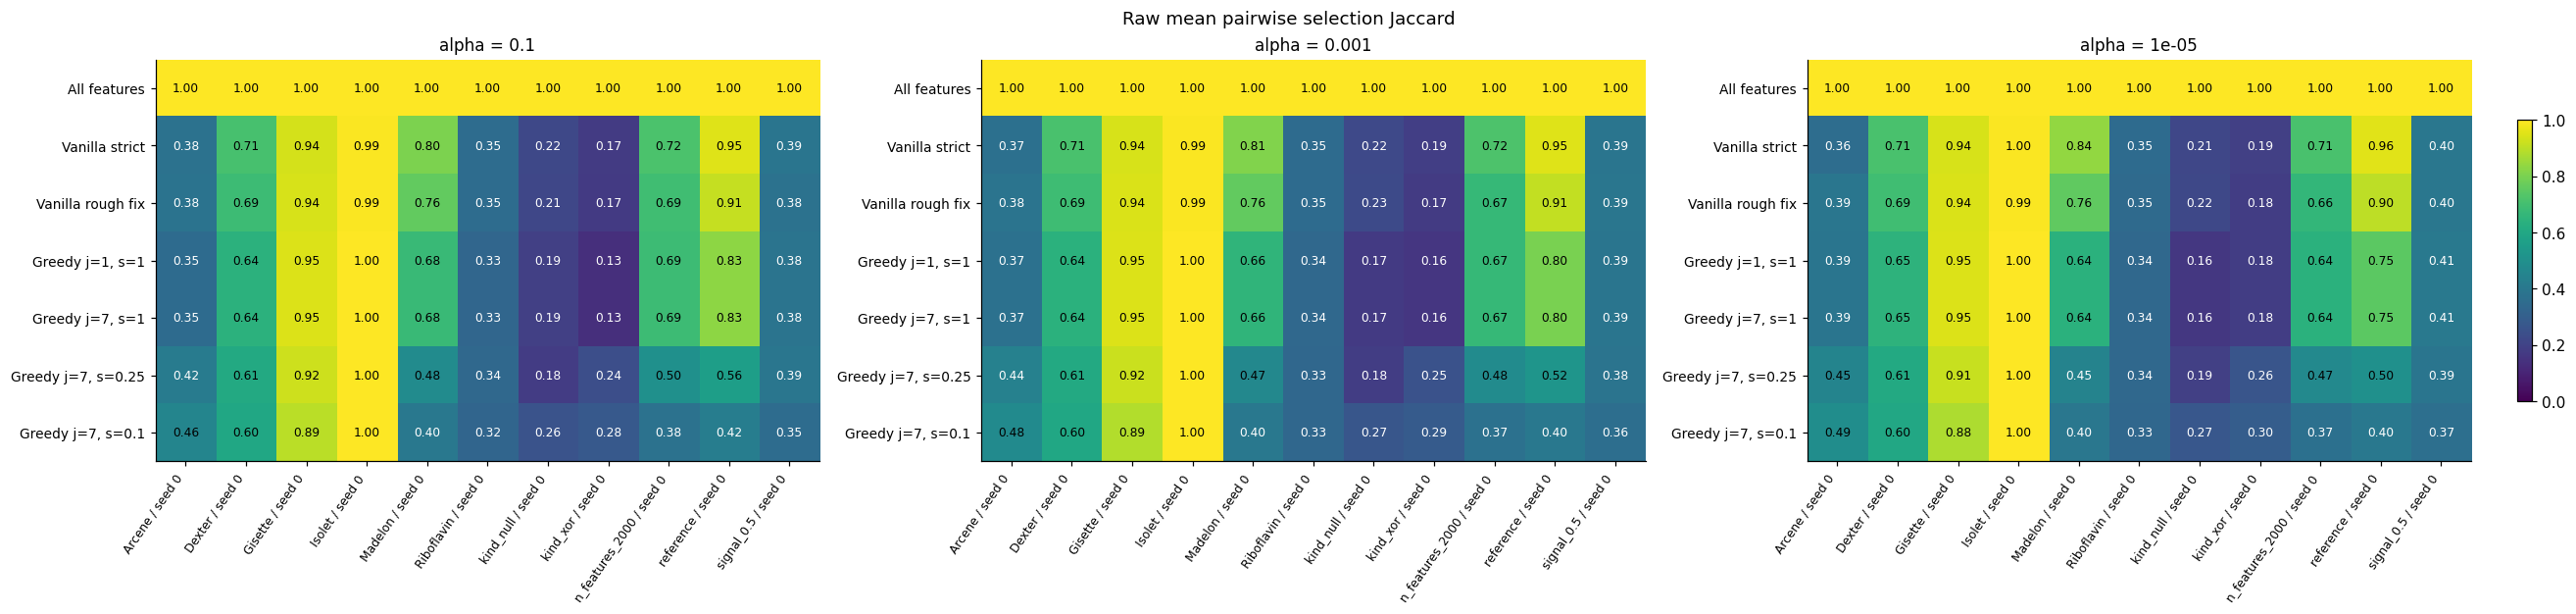

,Dataset,Data_Seed,Task,Estimator,Alpha,Method,Policy,Label,Role,Mean_Frequency,N_Features
7,kind_null,0,class,extra_trees,0.001,Greedy_jobs1_shadows1,selected,"Greedy j=1, s=1",Noise,0.0111,500
8,kind_null,0,class,extra_trees,0.001,Greedy_jobs7_shadows0.1,selected,"Greedy j=7, s=0.1",Noise,0.0949,500
9,kind_null,0,class,extra_trees,0.001,Greedy_jobs7_shadows0.25,selected,"Greedy j=7, s=0.25",Noise,0.0371,500
10,kind_null,0,class,extra_trees,0.001,Greedy_jobs7_shadows1,selected,"Greedy j=7, s=1",Noise,0.0111,500
11,kind_null,0,class,extra_trees,0.001,NoSelection,selected,All features,Noise,1.0000,500
...,...,...,...,...,...,...,...,...,...,...,...
226,signal_0.5,0,class,extra_trees,0.001,Vanilla,rough_fix,Vanilla rough fix,Noise,0.0111,475
227,signal_0.5,0,class,extra_trees,0.001,Vanilla,rough_fix,Vanilla rough fix,Proxy,0.2733,20
228,signal_0.5,0,class,extra_trees,0.001,Vanilla,strict,Vanilla strict,Direct,0.6000,5
229,signal_0.5,0,class,extra_trees,0.001,Vanilla,strict,Vanilla strict,Noise,0.0100,475


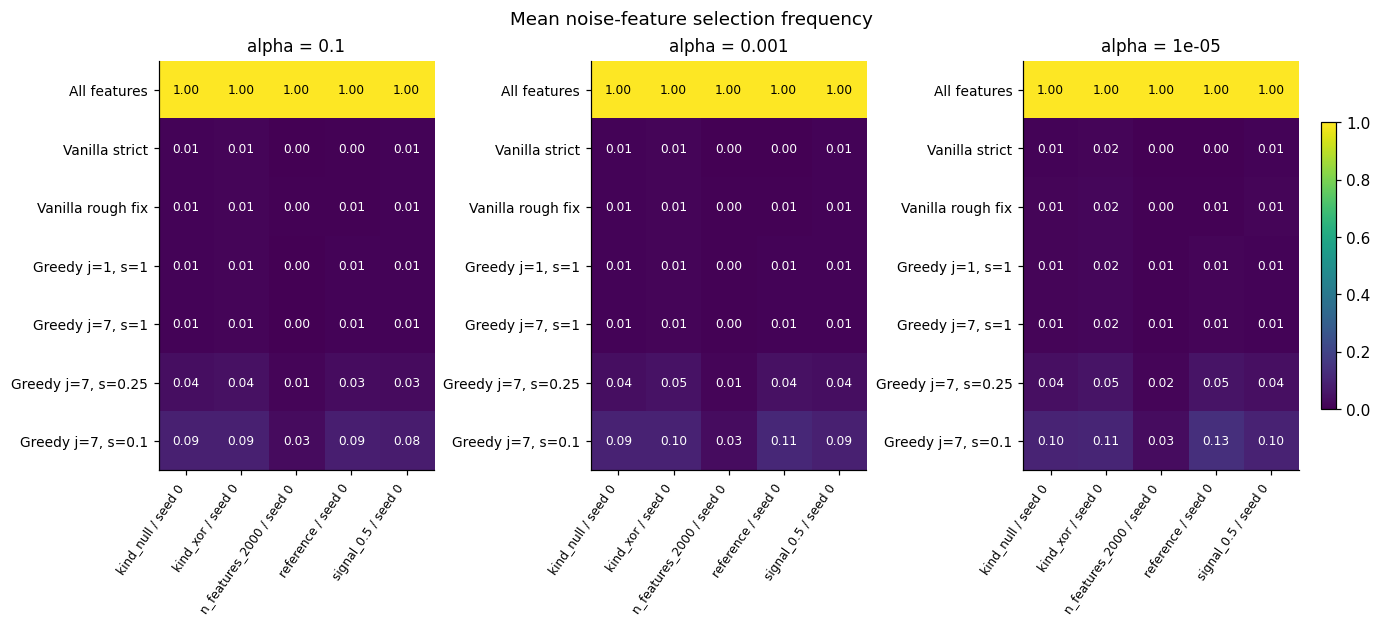

In [10]:
stability, frequency = ah.stability_tables(complete, run.manifest)
show(ah.heatmap(stability, "Mean_Pairwise_Jaccard", "Raw mean pairwise selection Jaccard", bounds=(0, 1)),
     "09_selection_stability")
frequency_roles = frequency.groupby(ah.GROUP + ["Label", "Role"]).Selection_Frequency.agg(
    Mean_Frequency="mean", N_Features="size").reset_index() if not frequency.empty else pd.DataFrame()
if not frequency_roles.empty:
    display(frequency_roles[frequency_roles.Alpha.eq(FOCUS_ALPHA)])
    noise_frequency = frequency_roles[frequency_roles.Role.eq("Noise")]
    show(ah.heatmap(noise_frequency, "Mean_Frequency", "Mean noise-feature selection frequency",
                    bounds=(0, 1)), "10_noise_selection_frequency")

## 6. Resource use and computation reuse

Resource totals below include **all observed jobs**, including incomplete blocks.
Vanilla strict/rough-fix rows count as one selector fit; NoSelection alpha copies
count as one baseline job. Only actually performed downstream fits contribute
actual downstream time. These sums exclude preprocessing and scheduling overhead
and are not total experiment wall time.

The memory figure uses complete blocks and one Vanilla policy. RSS is sampled
process-tree resident memory, including reusable workers; it may double-count
shared pages and miss short peaks. Peak increase is relative to the sampled
baseline, not a process-isolated allocation measurement.

,Quantity,Value,Unit
0,Logged result rows,3465.0000,rows
1,Completed method jobs (includes baseline),2640.0000,jobs
2,Selector fits (Vanilla policies counted once),2475.0000,fits
3,Actually performed downstream fits,2000.0000,fits
4,Selector fit time,32.0284,hours
5,Actual downstream fit time,0.4887,hours


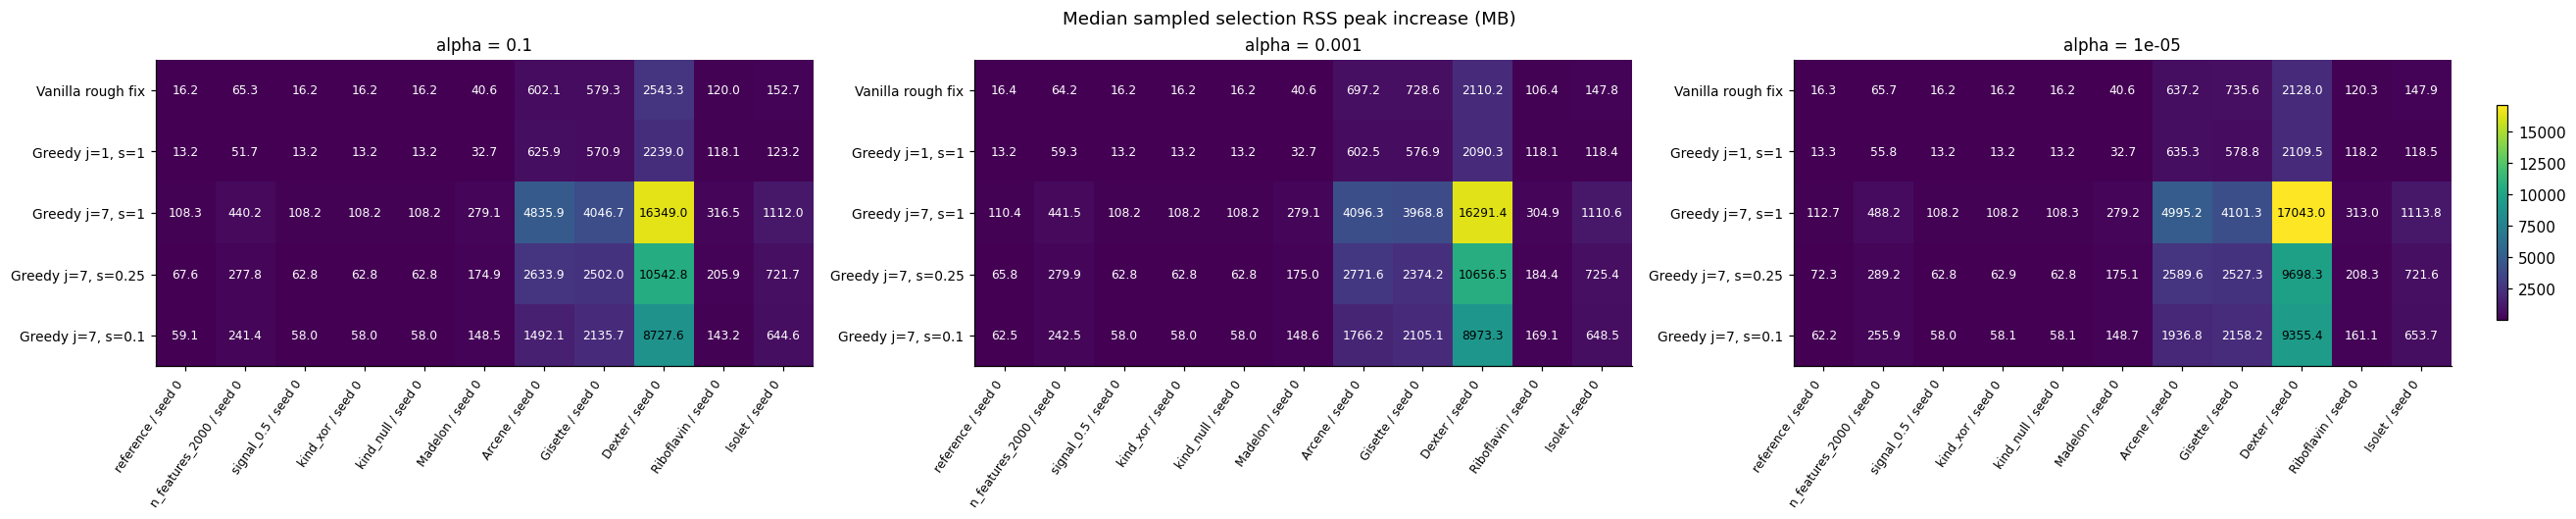

In [11]:
resources = ah.resource_accounting(observed)
display(resources)
memory_rows = complete[~complete.Method.eq("NoSelection") & ~complete.Policy.eq("strict")]
show(ah.heatmap(memory_rows, "RSS_Peak_Increase_MB", "Median sampled selection RSS peak increase (MB)",
                agg="median", fmt=".1f"), "11_memory_peak_increase")

## 7. Prespecified paired non-inferiority

For each dataset realization, task, estimator and alpha, define
$D = \mathrm{Score}_{candidate} - \mathrm{Score}_{Vanilla,rough\ fix}$.
Use the positive loss margin $\delta$ and test level frozen in the manifest:
$H_0: E[D] \leq -\delta$ versus $H_1: E[D] > -\delta$.

As in `benchmarks/runner/noninferiority.py`, the approximate corrected standard error is
$SE = \sqrt{(1/N + \overline{n_{test}/n_{train}})s_D^2}$, with $N-1$ t degrees of freedom.
The displayed bound is the **pointwise one-sided** lower bound, not a two-sided or
simultaneous interval. Zero-variance comparisons are flagged in the exported table.

Holm adjustment covers the **entire planned family**, including NoSelection
(231 tests for this manifest); missing tests are conservatively assigned p=1.
Numeric interim diagnostics use only complete blocks. **Decisions are withheld
until every planned block is complete**, and are also withheld for smoke runs.
Repeated inspection is not a sequential testing procedure. The single synthetic
seed supports conditional conclusions for that realization, not a population of
new generated datasets. Failure to establish NI means inconclusive, not inferior
or equivalent. A labelled **sensitivity line at one-sided level 0.025** (97.5% bound,
same Holm family) is reported next to the confirmatory decision; it does not replace it.
The augmented `GreedyCoupled` method is descriptive and never enters the family. Non-significant difference tests are never called equivalence.

Comparisons
Analysis_Status Decision                        Decision_Level_0.025                        
Final           Non-inferiority established     Non-inferiority established               30
                Non-inferiority not established Non-inferiority not established          135

,Dataset,Label,N_Pairs,Mean_Difference,Margin,Lower_One_Sided_CI,Lower_Bound_97.5,P_NI_Holm,Zero_Variance,Decision,Decision_Level_0.025
5,Arcene,"Greedy j=1, s=1",15,8.0543e-03,0.01,-0.0800,-0.0639,1.0000e+00,False,Non-inferiority not established,Non-inferiority not established
6,Arcene,"Greedy j=7, s=0.1",15,2.4053e-02,0.01,-0.0587,-0.0436,1.0000e+00,False,Non-inferiority not established,Non-inferiority not established
7,Arcene,"Greedy j=7, s=0.25",15,2.6122e-02,0.01,-0.0719,-0.0540,1.0000e+00,False,Non-inferiority not established,Non-inferiority not established
8,Arcene,"Greedy j=7, s=1",15,8.0543e-03,0.01,-0.0800,-0.0639,1.0000e+00,False,Non-inferiority not established,Non-inferiority not established
9,Arcene,All features,15,-3.1341e-02,0.01,-0.1016,-0.0887,1.0000e+00,False,Non-inferiority not established,Non-inferiority not established
20,Dexter,"Greedy j=1, s=1",15,-4.5583e-06,0.01,-0.0147,-0.0120,1.0000e+00,False,Non-inferiority not established,Non-inferiority not established
21,Dexter,"Greedy j=7, s=0.1",15,-5.6054e-04,0.01,-0.0221,-0.0182,1.0000e+00,False,Non-inferiority not established,Non-inferiority not established
22,Dexter,"Greedy j=7, s=0.25",15,2.2221e-03,0.01,-0.0262,-0.0210,1.0000e+00,False,Non-inferiority not established,Non-inferiority not established
23,Dexter,"Greedy j=7, s=1",15,-4.5583e-06,0.01,-0.0147,-0.0120,1.0000e+00,False,Non-inferiority not established,Non-inferiority not established
24,Dexter,All features,15,2.2212e-03,0.01,-0.0305,-0.0245,1.0000e+00,False,Non-inferiority not established,Non-inferiority not established


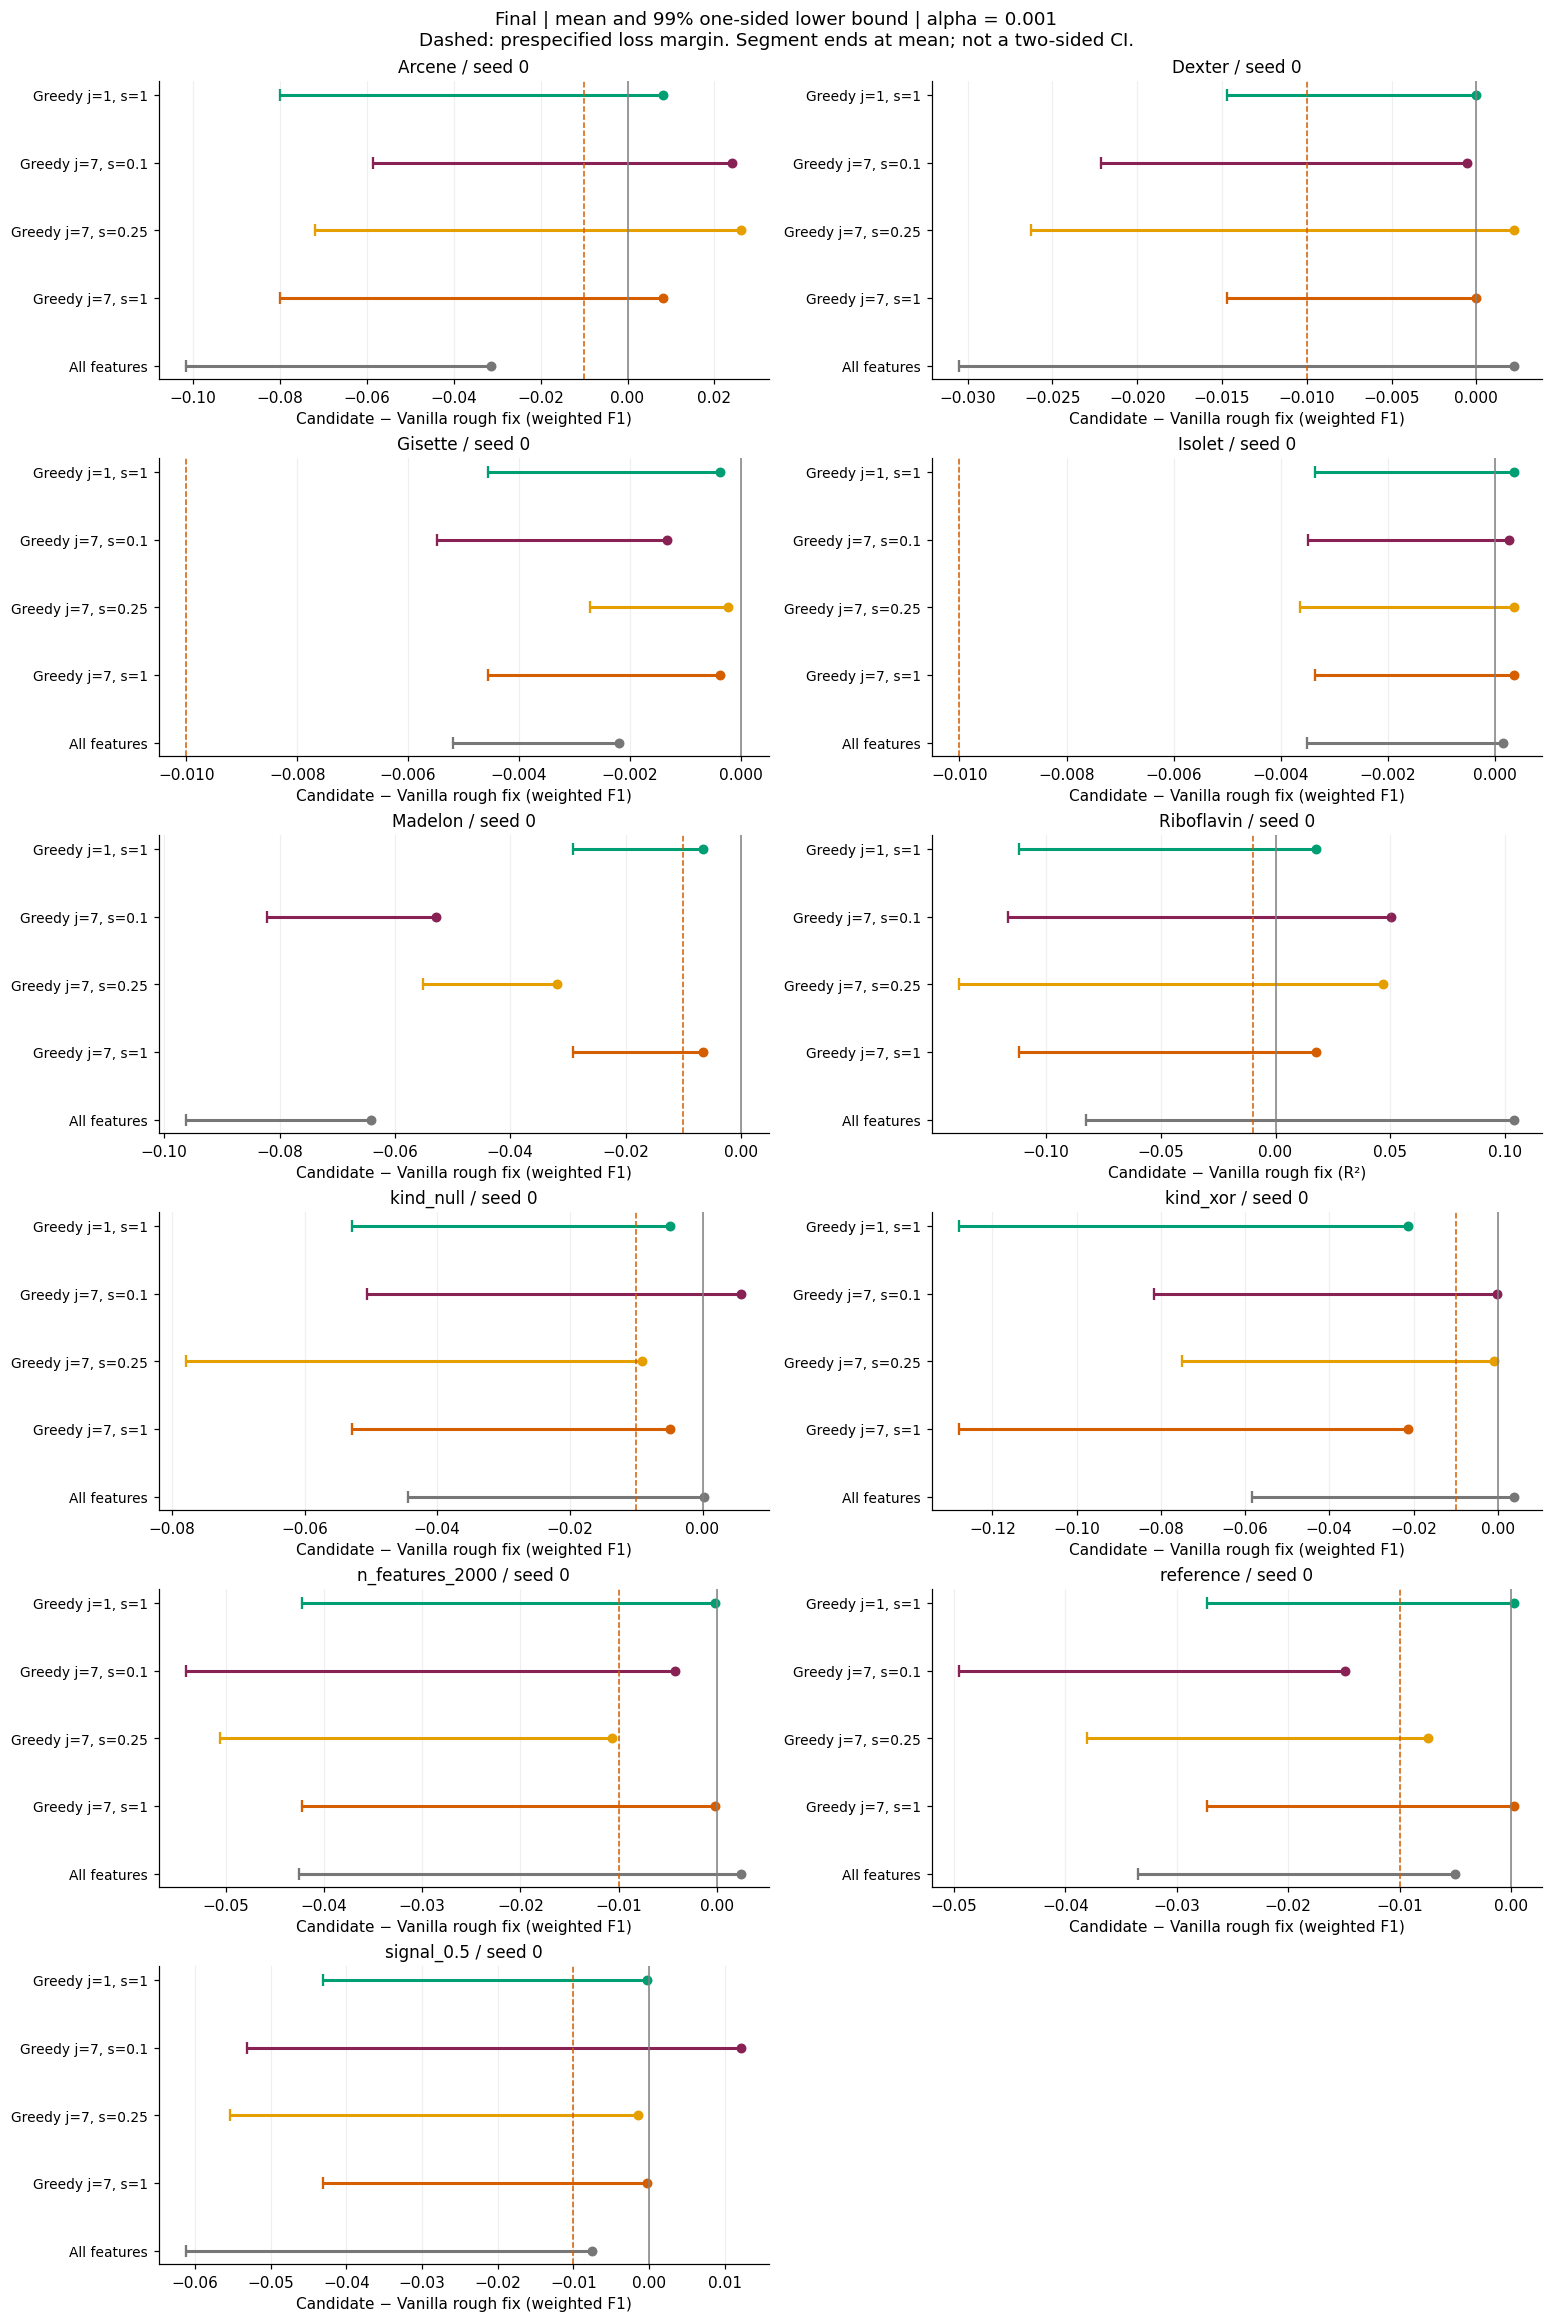

In [12]:
ni = ah.noninferiority(paired, run)
display(ni.groupby(["Analysis_Status", "Decision", "Decision_Level_0.025"]).size().rename("Comparisons").to_frame())
display(ni[ni.Alpha.eq(FOCUS_ALPHA)][["Dataset", "Label", "N_Pairs", "Mean_Difference", "Margin",
                                      "Lower_One_Sided_CI", "Lower_Bound_97.5", "P_NI_Holm", "Zero_Variance",
                                      "Decision", "Decision_Level_0.025"]])
show(ah.ni_plot(ni, FOCUS_ALPHA), "12_noninferiority_diagnostics")

## 8. Export and reproducibility record

The executed notebook keeps the plotted results inline. PDF and 300-dpi PNG copies,
CSV tables, the analyzed-row snapshot, source manifest, and input hashes are saved
under this analysis directory. Source checkpoints are never written. Re-running
refreshes the output directory: copy it first to preserve a prior dated snapshot.
`summary_observed` includes incomplete blocks; `summary_complete` and all paired
and inferential outputs use the stricter comparison cohort.

In [13]:
tables = {
    "coverage": run.coverage, "dataset_design": design,
    "summary_observed": observed_summary, "summary_complete": summary,
    "paired_comparisons": paired.drop(columns=["Selected_Features"]),
    "paired_speedups": speedups, "parallel_ablation": parallel_summary,
    "synthetic_confusion": confusion, "all_null_summary": null_summary,
    "selection_stability": stability, "synthetic_feature_frequency": frequency,
    "synthetic_frequency_by_role": frequency_roles,
    "resource_accounting": resources, "noninferiority": ni,
}
ah.export_tables(run, tables, OUTPUT_DIR)
display(Markdown(f"**Exported {len(tables)} tables and all figures** to `{OUTPUT_DIR.relative_to(ROOT)}`.  \n"
                 f"Snapshot status: **{status}**.  \n"
                 "Rerun after the remaining experiment jobs finish to refresh coverage and enable final NI decisions."))

**Exported 14 tables and all figures** to `benchmarks\analysis\publication\outputs\run_20260926_102546_793908`.  
Snapshot status: **COMPLETE DESIGN**.  
Rerun after the remaining experiment jobs finish to refresh coverage and enable final NI decisions.